In [2]:
%matplotlib inline
import warnings
import torch
import math
import time
import os
import matplotlib.pyplot as plt
from itertools import cycle
from datasets import Dataset
from torch.utils.data import DataLoader
from transformers import AutoTokenizer
from torch.optim.lr_scheduler import _LRScheduler
warnings.filterwarnings("ignore")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)           

c:\Users\kevin\Desktop\gpt-from-scratch\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


cuda


### Download Pretraining Dataset

In [3]:
from datasets import load_dataset
dataset = load_dataset("EleutherAI/wikitext_document_level", "wikitext-2-raw-v1", split="train")

### Tokenizing & Chunking

In [4]:
import tiktoken
tokenizer = tiktoken.get_encoding("gpt2")

print("Vocabulary size:", tokenizer.n_vocab)
print("End of text token:", tokenizer.eot_token)
print("Example tokenization:", tokenizer.encode("Hello world!"))

Vocabulary size: 50257
End of text token: 50256
Example tokenization: [15496, 995, 0]


In [5]:
# Convert entire dataset into a single string
all_text = ""
all_data = dataset["page"]
for example in all_data:
    all_text += "<page>" + example + "</page>"

# Tokenize the entire text at once
tokenized_text = tokenizer.encode(all_text)

In [6]:
# Create a function that generates a dataset of examples for llm
def get_dataset(num_examples, context_window_length, test_split=0.1):
    input_blocks = []
    target_blocks = []
    # Use a sliding window to create input/target
    for i in range(0, len(tokenized_text), context_window_length+1):
        block = tokenized_text[i:i+context_window_length+1]
        if len(block) < context_window_length + 1:
            continue
        input_seq = block[:-1]
        target_seq = block[1:]

        input_blocks.append(input_seq)
        target_blocks.append(target_seq)

        if len(input_blocks) >= num_examples:
            break

    # Convert to tensors for pytorch and move to gpu
    inputs = torch.tensor(input_blocks, dtype=torch.long).to(device)
    targets = torch.tensor(target_blocks, dtype=torch.long).to(device)

    # Calculate train/test split point
    split_idx = int(num_examples*(1-test_split))

    # Split into train/test
    train_inputs = inputs[:split_idx]
    train_targets = targets[:split_idx]
    test_inputs = inputs[split_idx:]
    test_targets = targets[split_idx:]

    return train_inputs, train_targets, test_inputs, test_targets

i, o, _, _ = get_dataset(2, 4, 0)
print("Input Shape: ", i.shape)
print("Output Shape: ", o.shape)
print("Input Example: ")
print(i)
print("Output Example: ")
print(o)

Input Shape:  torch.Size([2, 4])
Output Shape:  torch.Size([2, 4])
Input Example: 
tensor([[   27,  7700,    29,   796],
        [18354,  7496, 17740,  6711]], device='cuda:0')
Output Example: 
tensor([[ 7700,    29,   796,   569],
        [ 7496, 17740,  6711,   796]], device='cuda:0')


### Config Object

In [7]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# A simple configuration container
class GPTConfig:
    def __init__(
            self,
            vocab_size, # size of the vocab, from tokenizer
            n_layer, # number of transformer blocks
            n_head, # number of attention heads for each transformer block
            n_embd, # embedding dimension for each token
            seq_len, # sequence length for the model: "context window"
    ):
        self.vocab_size = vocab_size
        self.n_layer = n_layer
        self.n_head = n_head
        self.n_embd = n_embd
        self.seq_len = seq_len

test_config = GPTConfig(
    vocab_size=tokenizer.n_vocab,
    n_layer=2,
    n_head=3,
    n_embd=6,
    seq_len=4,
)

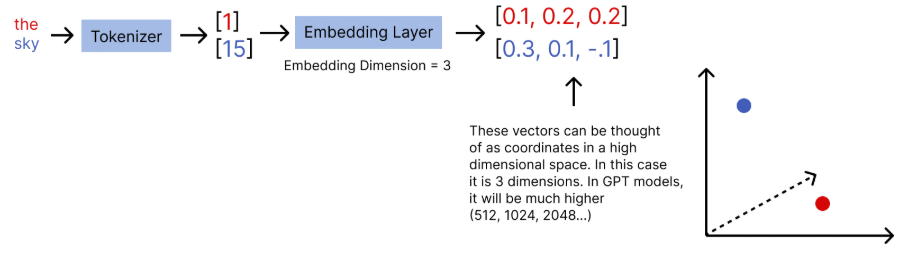
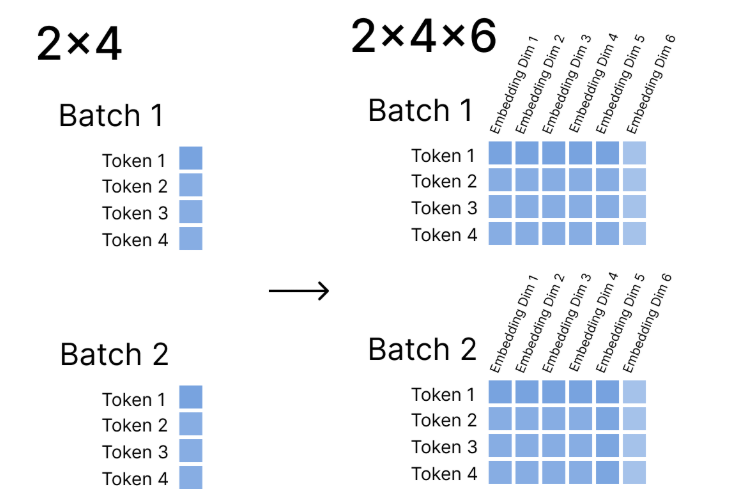

### Embedding Layer

In [8]:
token_embedding = nn.Embedding(test_config.vocab_size, test_config.n_embd).to(device)
test_batch_inputs, _, _, _ = get_dataset(2, test_config.seq_len, 0)
print("Batch shape: ", test_batch_inputs.shape, "Batch x Seq Len")
print("After embedding: ", token_embedding(test_batch_inputs).shape, "Batch x Seq Len x Embedding Dim")
print("")
print("Before embedding")
print(test_batch_inputs)
print("After embedding")
print(token_embedding(test_batch_inputs))

Batch shape:  torch.Size([2, 4]) Batch x Seq Len
After embedding:  torch.Size([2, 4, 6]) Batch x Seq Len x Embedding Dim

Before embedding
tensor([[   27,  7700,    29,   796],
        [18354,  7496, 17740,  6711]], device='cuda:0')
After embedding
tensor([[[ 2.0009,  0.3029, -0.8539, -1.2123, -0.3827,  0.9270],
         [-0.3831, -0.5370, -0.9390,  1.0786,  1.0611,  0.7882],
         [-0.6498,  0.3093, -1.4767, -0.3807,  0.1845,  1.3205],
         [-1.4585,  1.7198,  0.8545, -0.6087,  1.1709,  0.8147]],

        [[ 1.3920, -0.2322,  1.0611,  0.3695,  0.2856, -1.1992],
         [ 0.1858,  0.1950, -0.2575,  0.3369, -1.7634, -0.4751],
         [-0.9855, -1.3501,  0.1953, -0.5806, -1.2797,  3.1484],
         [-0.8565,  0.3830,  1.1196,  0.5413,  0.6289,  0.5459]]],
       device='cuda:0', grad_fn=<EmbeddingBackward0>)


### Positional Encoding Layer
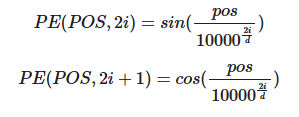

In [9]:
# Positional encoding allows the model to differentiate the two usages within the same instance
def get_position_encodng(seq_len, d, n=10000):
    """
    Computes the positional encoding matrix of shape (seq_len, d).
    
    Args:
        seq_len (int): Length of the sequence.
        d (int): Dimension of the embedding.
        n (float): The base for the exponential term (default 10000 in many Transformer implementations).
    
    Returns:
        torch.Tensor: A tensor of shape (seq_len, d) containing the positional encodings.
    """
    P = torch.zeros(seq_len, d).to(device)
    for pos in range(seq_len):
        for i in range(0, d//2):
            P[pos, 2 * i] = math.sin(pos / (n ** ((2 * i) / d))) # even index
            if i + 1 < d: # odd index
                P[pos, 2*i + 1] = math.cos(pos / (n ** ((2 * i) / d)))
    return P.unsqueeze(0) # add an extra dim

"""
dimension index:
0   1   2   3   4   5
↓   ↓   ↓   ↓   ↓   ↓
sin cos sin cos sin cos
"""

position_encoding = get_position_encodng(seq_len=test_config.seq_len, d=test_config.n_embd)
print("Position encoding shape: ", position_encoding.shape)

Position encoding shape:  torch.Size([1, 4, 6])


In [10]:
test_embeddings = token_embedding(test_batch_inputs)
test_embeddings_with_pos = test_embeddings + position_encoding
print("Token embeddings shape: ", test_embeddings.shape)
print("Position encodings shape: ", position_encoding.shape)
print("Sum of token embeddings and position encodings: ", test_embeddings_with_pos.shape)

Token embeddings shape:  torch.Size([2, 4, 6])
Position encodings shape:  torch.Size([1, 4, 6])
Sum of token embeddings and position encodings:  torch.Size([2, 4, 6])


### Masked Multiheaded Self-Attention

In [11]:
# Self Attention - allows every token to "talk" to the other tokens. 
# A word's meaning into a combination of all the other words in the context window
# Decomposes the token_embedding_matrix_with_position_encodings into queries, keys, and values
# Wq, Wk, Wv -> Q, K, V

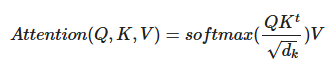
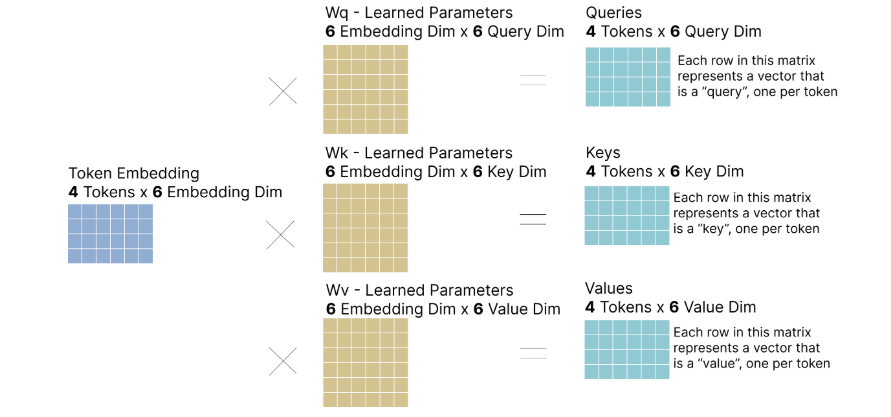

In [12]:
# Q, K, V = XWq, XWk, XWv, where X = token_embedding + positional_embedding and W represents a parameter

# Q: n vectors where each vector is a query about the corresponding word that could be answered by some combinations of other words
# K: n vectors where each vector helps answer queries
# V: the actual content/information that each token has to offer; weighted by the similarities of the K, Q -> final output of self attention

# QK^T -> calculate how well each token query matches each key
# A high dot product -> vectors point in a direction near each other -> two tokens are important to take into account together
# QK^T: Similarity Matrix -> softmax() -> how strong of a match key is to the query of the row

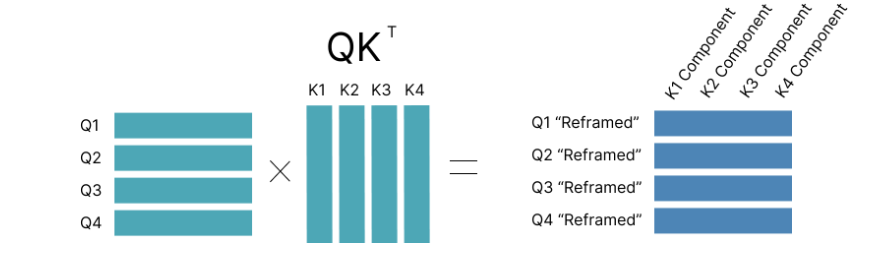

In [13]:
# QK^T/sqrt(dk): scale down by the length of Q/K vector to make the final output of the softmax more stable
# dk: the length of the Q/K vector
# softmax(QK^T/sqrt(dk)): every row results in a probability distribution

In [14]:
# V: column matrix where each column is a learned feature, and each element of those vectors is the value of that feature for the token in that row
# contain information about specific learned features for each token; adjusted by the weights from softmax(QK^T/sqrt(dk))
# softmax(QK^T/sqrt(dk))V: computes how relevant each token is to the other tokens based on the specific questions we ask

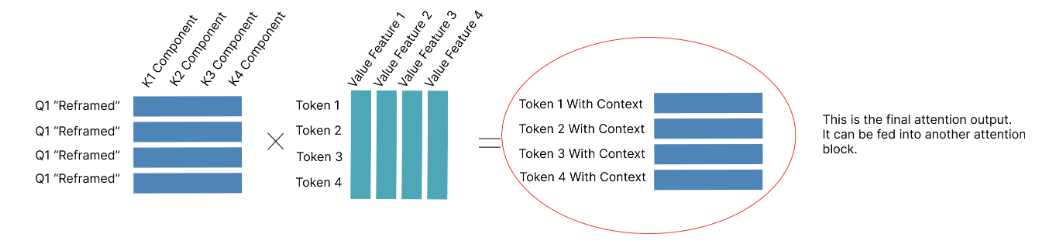
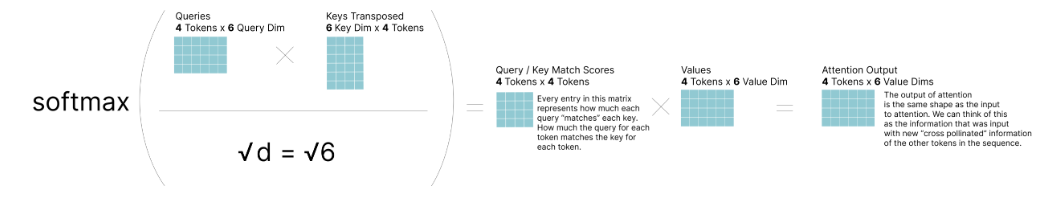

In [15]:
class SelfAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.Wq = nn.Parameter(torch.randn(config.n_embd, config.n_embd)).to(device)
        self.Wk = nn.Parameter(torch.randn(config.n_embd, config.n_embd)).to(device)
        self.Wv = nn.Parameter(torch.randn(config.n_embd, config.n_embd)).to(device)

    def forward(self, x):
        print("Attention input shape: ", x.shape)
        print("")
        print("Query weights shape", self.Wq.shape)
        print("Key weights shape", self.Wk.shape)
        print("Value weights shape", self.Wv.shape)
        queries = x @ self.Wq # Q
        keys = x @ self.Wk    # K
        values = x @ self.Wv  # V
        print("")
        print("Queries shape: ", queries.shape)
        print("keys shape: ", keys.shape)
        print("values shape: ", values.shape)

        qkt = queries @ keys.transpose(-2, -1) # QK^T [Batch, Seq, Dim]
        qkt_scaled = qkt / math.sqrt(queries.size(-1)) # QK^T/sqrt(dk)
        qkt_softmax = F.softmax(qkt_scaled, dim=-1) # softmax row-wise
        print("")
        print("QK^T shape", qkt.shape)

        attn_output = qkt_softmax @ values
        print("")
        print("Attention output shape: ", attn_output.shape)
        return attn_output

attention = SelfAttention(test_config)
test_out = attention(test_embeddings_with_pos)

Attention input shape:  torch.Size([2, 4, 6])

Query weights shape torch.Size([6, 6])
Key weights shape torch.Size([6, 6])
Value weights shape torch.Size([6, 6])

Queries shape:  torch.Size([2, 4, 6])
keys shape:  torch.Size([2, 4, 6])
values shape:  torch.Size([2, 4, 6])

QK^T shape torch.Size([2, 4, 4])

Attention output shape:  torch.Size([2, 4, 6])


### Causal Self Attention

In [16]:
# How to make it auto-regressive
# Without knowing the future token -> mask the matrices
# Perfom the masking after the QK^T operation
# Masking process makes the output of the softmax operation 0
    # - The query for token 1 is only able to be reframed as a combination of token 1
    # - The query for token 2 is only able to be reframed as a combination of tokens 1 and 2
    # - The query for token 3 is only able to be reframed as a combination of tokens 1,2, and 3
    # - etc...

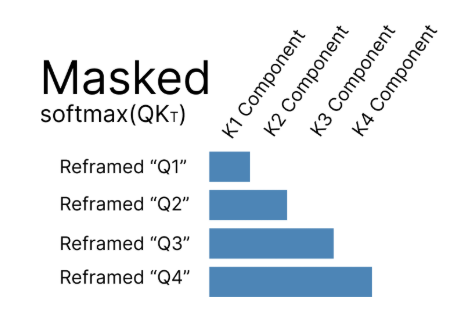

In [17]:
class CausalSelfAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.Wq = nn.Parameter(torch.randn(config.n_embd, config.n_embd)).to(device)
        self.Wk = nn.Parameter(torch.randn(config.n_embd, config.n_embd)).to(device)
        self.Wv = nn.Parameter(torch.randn(config.n_embd, config.n_embd)).to(device)

    def forward(self, x):
        seq_len = x.shape[1] # number of tokens / context window length
        queries = x @ self.Wq # Q
        keys = x @ self.Wk    # K
        values = x @ self.Wv  # V
        qkt = queries @ keys.transpose(-2, -1)
        qkt_scaled = qkt / math.sqrt(queries.size(-1))

        # Masking
        causal_mask = torch.triu(torch.ones(seq_len, seq_len, device=x.device), diagonal=1)
        causal_mask = causal_mask.masked_fill(causal_mask == 1, float('-inf')) # Upper triangle where element is 1 is masked with -inf
        qkt_scaled = qkt_scaled + causal_mask 

        qkt_softmax = F.softmax(qkt_scaled, dim=-1)
        attn_output = qkt_softmax @ values
        return attn_output
"""
[[0, 1, 1, 1],
 [0, 0, 1, 1],
 [0, 0, 0, 1],
 [0, 0, 0, 0]]
 ->
[[0,   -inf, -inf, -inf],
 [0,    0,   -inf, -inf],
 [0,    0,    0,   -inf],
 [0,    0,    0,    0]]

[2.1, -inf, -inf, -inf] -> softmax = [1.0, 0.0, 0.0, 0.0]
"""
attention = CausalSelfAttention(test_config)
test_out = attention(test_embeddings_with_pos)
print(test_out.shape)


torch.Size([2, 4, 6])


### Multi-Headed Causal Self Attention

In [18]:
# Splits the attention operation in parallel, allowing multiple "heads" to each have their own learned QKV weights
# Each head focuses on different aspects such as grammatical structure, semantic meaning, and real-world meaning
# The token's relationship viewed through different heads differs

# Steps in multi-headed causal self attention
# ==================================================================================================================
# Step 1 - Multiply Input by Wqkv
# Concatenate Wq, Wk, Wv
# X x Wqkv^T = QKV
# ==================================================================================================================
# Step 2 - Split the Q, K, V Matrices
# Can split out back to individual matrices
# ==================================================================================================================
# Step 3 - Reshape the Q, K, V Matrices Into Heads
# Divide the matrices by the number of heads
# ==================================================================================================================
# Step 4 - QK^T
# Perform the operation in parallel
# ==================================================================================================================
# Step 5 - Mask Before Softmax
# Take the result and apply the causal mask before softmax operation
# ==================================================================================================================
# Step 6 - Softmax & Multiply by V
# Same operation as above
# ==================================================================================================================
# Step 7 - Merge Heads
# Merge V attended back together into a single matrix before FFN
# ==================================================================================================================
# Step 8 - Projection Layer
# V "Attended" x proj^T
# ==================================================================================================================

In [19]:
class MultiHeadAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        assert config.n_embd % config.n_head == 0, "n_embd must be divisible by n_head"

        self.n_head = config.n_head
        self.n_embd = config.n_embd
        self.head_dim = config.n_embd // config.n_head

        self.Wqkv = nn.Linear(self.n_embd, 3 * self.n_embd, bias=False).to(device)
        self.proj = nn.Linear(self.n_embd, self.n_embd, bias=False).to(device)

        mask = torch.tril(
            torch.ones(config.seq_len, config.seq_len, device=device, dtype=torch.bool)
        )
        self.register_buffer("causal_mask", mask.view(1, 1, config.seq_len, config.seq_len)) # fixed tensor memory

    def forward(self, x):
        B, seq_len, n_embd = x.shape # batch, time, channels

        # Step 1
        qkv = self.Wqkv(x)
        # Step 2
        q, k, v = qkv.split(n_embd, dim=2)
        # Step 3
        # (B, T, C) -> (B, seq_len, n_head, head_dim) -> (B, n_head, seq_len, head_dim)
        q = q.view(B, seq_len, self.n_head, self.head_dim).transpose(1, 2)
        k = k.view(B, seq_len, self.n_head, self.head_dim).transpose(1, 2)
        v = v.view(B, seq_len, self.n_head, self.head_dim).transpose(1, 2)
        # Step 4
        att = (q @ k.transpose(-2, -1)) / math.sqrt(self.head_dim)
        # Step 5
        mask = self.causal_mask[:, :, :seq_len, :seq_len]
        att = att.masked_fill(~mask, float("-inf")) # ~mask == True -> -inf
        # Step 6
        att = F.softmax(att, dim=-1)
        y = att @ v
        # Step 7
        y = y.transpose(1, 2).contiguous().view(B, seq_len, n_embd)
        # Step 8
        y = self.proj(y)
        return y

multihead_attn = MultiHeadAttention(test_config)
test_out = multihead_attn(test_embeddings_with_pos)
print(test_out.shape)

torch.Size([2, 4, 6])


### Layer Normalization Layers

In [20]:
# Normalizes the value of the incoming matrix across the feature dimension
# Used to stabilize training and achieve faster convergence

In [21]:
# Feedforward layer
# Applies the same transformation to each token in parallel
# Gaussian Error Linear Unit (ReLU) activation function

class GPTBlock(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.mha = MultiHeadAttention(config)
        self.ln1 = nn.LayerNorm(config.n_embd).to(device)
        self.ffn = nn.Sequential(
            nn.Linear(config.n_embd, 4 * config.n_embd),
            nn.GELU(),
            nn.Linear(4 * config.n_embd, config.n_embd)
        ).to(device)
        self.ln2 = nn.LayerNorm(config.n_embd).to(device)

    def forward(self, x):
        x = x + self.mha(self.ln1(x))
        x = x + self.ffn(self.ln2(x))
        return x

block = GPTBlock(test_config)
test_out = block(test_embeddings_with_pos)
print(test_out.shape)

torch.Size([2, 4, 6])


In [22]:
class GPTModel(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.token_embedding = nn.Embedding(config.vocab_size, config.n_embd).to(device)
        self.position_encoding = get_position_encodng(config.seq_len, config.n_embd)
        self.blocks = nn.Sequential(*[GPTBlock(config) for _ in range(config.n_layer)])
        self.ln_f = nn.LayerNorm(config.n_embd).to(device)
        self.head = nn.Linear(config.n_embd, config.vocab_size).to(device)

    def forward(self, x):
        x = self.token_embedding(x) + self.position_encoding
        x = self.blocks(x)
        x = self.ln_f(x)
        return self.head(x)

gpt = GPTModel(test_config)
print(test_batch_inputs.shape)
test_out = gpt(test_batch_inputs)
print(test_out.shape)

torch.Size([2, 4])
torch.Size([2, 4, 50257])


### Objective Function

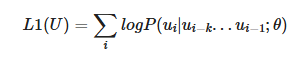

In [ ]:
# U is the sequence of text 
# ui is the current token of the sequence
# ui-k...ui-1 are the previous k tokens (context window)
# P(ui|ui-k...ui-1) is the probability of predicting ui given precious tokens and the model's parameter theta
# Take the log of this calue for its useful properties in optimization
# Take the sum across all the tokens in sequence

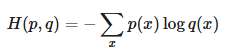

In [ ]:
# Maximizing the objective function is essentially the same as minimizing the cross entropy loss function
# p(x) is the true class discrete probability distribution
# q(x) is the predicted class discrete probability distribution

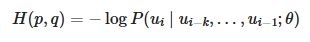

In [ ]:
# During training, we use a one-hot encoded vector for the true distribution, so p(x) is 1 for the correct token, and 0 for all other tokens
# Therefore, we can remove the sum and simplify the cross entropy loss to what is shown as above

In [24]:
# Test One: Overfitting
# Train the model with a small dataset (10 examples) and see if we can get the model to memorize/overfit to the dataset

batch_size = 10
sequence_len = 128
num_steps = 1000
train_inputs, train_targets, _, _ = get_dataset(10, sequence_len, 0)
config = GPTConfig(
    vocab_size=tokenizer.n_vocab,
    n_layer=4,
    n_head=4,
    n_embd=128,
    seq_len=sequence_len,
)

model = GPTModel(config)
optimizer = torch.optim.Adam(model.parameters(), lr=5e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.2, patience=20, min_lr=5e-6, threshold=1e-4)

i = 1
losses = []

while i < num_steps:
    for j in range(0, len(train_inputs), batch_size):
        x = train_inputs[j:j+batch_size]
        y = train_targets[j:j+batch_size]

        # Forward pass
        logits = model(x)
        loss = F.cross_entropy(logits.view(-1, logits.size(-1)), y.view(-1))
        loss.backward()

        # Gradient clipping
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        losses.append(loss.item())
        optimizer.step()
        optimizer.zero_grad()

        loss =loss.item()
        scheduler.step(loss)

        lr = optimizer.param_groups[0]["lr"]
        print(f"Step {i+1}/{num_steps}, Loss: {loss}, LR: {lr}")

        i += 1

Step 2/1000, Loss: 11.011226654052734, LR: 0.0005
Step 3/1000, Loss: 10.809198379516602, LR: 0.0005
Step 4/1000, Loss: 10.619455337524414, LR: 0.0005
Step 5/1000, Loss: 10.444939613342285, LR: 0.0005
Step 6/1000, Loss: 10.285551071166992, LR: 0.0005
Step 7/1000, Loss: 10.139318466186523, LR: 0.0005
Step 8/1000, Loss: 10.003280639648438, LR: 0.0005
Step 9/1000, Loss: 9.874246597290039, LR: 0.0005
Step 10/1000, Loss: 9.749288558959961, LR: 0.0005
Step 11/1000, Loss: 9.62587833404541, LR: 0.0005
Step 12/1000, Loss: 9.5018892288208, LR: 0.0005
Step 13/1000, Loss: 9.375629425048828, LR: 0.0005
Step 14/1000, Loss: 9.24593734741211, LR: 0.0005
Step 15/1000, Loss: 9.112296104431152, LR: 0.0005
Step 16/1000, Loss: 8.975004196166992, LR: 0.0005
Step 17/1000, Loss: 8.835304260253906, LR: 0.0005
Step 18/1000, Loss: 8.695266723632812, LR: 0.0005
Step 19/1000, Loss: 8.557205200195312, LR: 0.0005
Step 20/1000, Loss: 8.422330856323242, LR: 0.0005
Step 21/1000, Loss: 8.289654731750488, LR: 0.0005
Step 

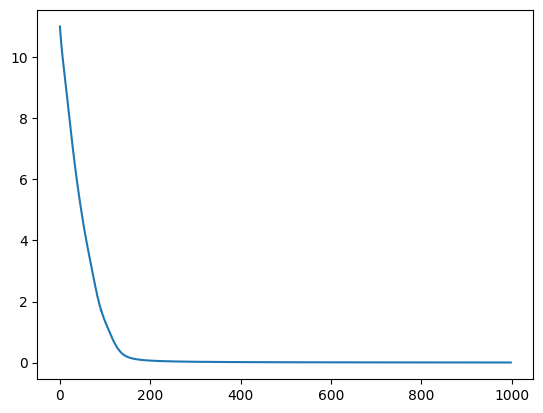

In [25]:
plt.plot(losses)

In [35]:
# Test Two: Memorization
def inference(prompt, max_new_tokens):
    tokens = tokenizer.encode(prompt)
    for _ in range(max_new_tokens):
        num_tokens = len(tokens)
        tokens_padded = tokens + [tokenizer.eot_token] * (config.seq_len - num_tokens)
        tokens_padded = torch.tensor(tokens_padded).unsqueeze(0).to(device)
        logits = model(tokens_padded)
        predicted_token = torch.argmax(logits[0, num_tokens-1, :]).item()
        tokens.append(predicted_token)
    return tokenizer.decode(tokens)

print("Originial: ", tokenizer.decode(train_inputs[2].tolist())[:90])
print("Predicted: ", inference(" director Takeshi Ozawa . A large team of writers handled the script", max_new_tokens=6))

Originial:   Takeshi Ozawa . A large team of writers handled the script . The game 's opening theme wa
Predicted:   director Takeshi Ozawa . A large team of writers handled the script . The game 's opening


In [ ]:
# Huggingface Streaming Dataset

ds = load_dataset("abisee/cnn_dailymail", "3.0.0", split="train")
hf_tokenizer = AutoTokenizer.from_pretrained("gpt2")

def check_dataset_exists():
    try:
        load_dataset("parquet", data_files="cnn_dailymail_train.parquet", split="train")
        load_dataset("parquet", data_files="cnn_dailymail_test.parquet", split="train")
        return True
    except FileNotFoundError:
        return False

if not check_dataset_exists():
    print("Tokenized dataset does not exist locally... Generating and saving to disk.")

    def tokenize_and_chunk(dataset, tokenizer, chunk_size=512, train_rows=100_000, test_rows=500):
        """
        Tokenizes and chunks the dataset into fixed-length 512-token segments.
        The 'target' sequence is shifted left by 1 token.
        Stops after generating `train_rows + test_rows` tokenized chunks.
        """
        buffer = []
        row_count = 0

        for example in dataset:
            tokens = tokenizer(example["article"], truncation=False, padding=False)["input_ids"]
            buffer.extend(tokens)

            while len(buffer) >= chunk_size + 1:
                if row_count >= (train_rows + test_rows):
                    return

                input_chunk = buffer[:chunk_size]
                target_chunk = buffer[1:chunk_size + 1] # shifted by 1 token

                split = "train" if row_count < train_rows else "test"
                yield {
                    "split": split,
                    "input": input_chunk,
                    "target": target_chunk
                }

                buffer = buffer[chunk_size:] # remove used tokens
                row_count += 1

    TRAIN_ROWS = 1400000
    TEST_ROWS = 500
    CHUNK_SIZE = 128

    # Convert generator to a Hugging Face Dataset
    tokenized_ds = Dataset.from_generator(lambda: tokenize_and_chunk(ds, hf_tokenizer, chunk_size=CHUNK_SIZE, train_rows=TRAIN_ROWS, test_rows=TEST_ROWS))
    # Split the dataset into "train" and "test"
    dataset_splits = tokenized_ds.train_test_split(test_size=TEST_ROWS / (TRAIN_ROWS + TEST_ROWS), seed=42)

    # Save to disk
    dataset_splits["train"].to_parquet("cnn_dailymail_train.parquet")
    dataset_splits["test"].to_parquet("cnn_dailymail_test.parquet")

    print(f"Saved {TRAIN_ROWS} train rows and {TEST_ROWS} test rows.")
else:
    print("Tokenized dataset already exists locally.")


Tokenized dataset does not exist locally... Generating and saving to disk.


Generating train split: 0 examples [00:00, ? examples/s]Token indices sequence length is longer than the specified maximum sequence length for this model (1194 > 1024). Running this sequence through the model will result in indexing errors
Generating train split: 1400500 examples [08:39, 2697.87 examples/s]
Creating parquet from Arrow format: 100%|██████████| 1/1 [00:00<00:00, 32.60ba/s]

Saved 1400000 train rows and 500 test rows.


In [40]:
import pandas as pd
df = pd.read_parquet("cnn_dailymail_test.parquet")
df.head()

,split,input,target
0,train,"[286, 262, 33017, 19639, 764, 1881, 1074, 11, ...","[262, 33017, 19639, 764, 1881, 1074, 11, 543, ..."
1,train,"[3822, 13, 887, 3583, 1816, 11706, 284, 9689, ...","[13, 887, 3583, 1816, 11706, 284, 9689, 262, 9..."
2,train,"[428, 1637, 11, 257, 2839, 1664, 1276, 1956, 1...","[1637, 11, 257, 2839, 1664, 1276, 1956, 11512,..."
3,train,"[1294, 6322, 13, 6363, 18476, 11, 262, 29986, ...","[6322, 13, 6363, 18476, 11, 262, 29986, 11, 55..."
4,train,"[257, 2576, 11, 407, 1865, 257, 2415, 1, 19713...","[2576, 11, 407, 1865, 257, 2415, 1, 19713, 379..."


In [49]:
# Modified Training Loop
batch_size = 64
sequence_len = 128
num_steps = 150000
accumulation_steps = 100

# Reload the train and test datasets
train_ds = load_dataset("parquet", data_files="cnn_dailymail_train.parquet", split="train")
test_ds = load_dataset("parquet", data_files="cnn_dailymail_test.parquet", split="train")

# Convert dataset to PyTorch format
train_ds.set_format("torch", columns=["input", "target"])
test_ds.set_format("torch", columns=["input", "target"])

# Create DataLoaders for training and testing
train_dataloader = cycle(DataLoader(train_ds, batch_size=batch_size, shuffle=False))
test_dataloader = DataLoader(test_ds, batch_size=batch_size, shuffle=False)

config = GPTConfig(
    vocab_size=hf_tokenizer.vocab_size,
    n_layer=8,
    n_head=8,
    n_embd=128,
    seq_len=sequence_len,
)
model = GPTModel(config)

use_existing_model = os.path.exists("./pretrain_final.pth")

if use_existing_model:
    model = torch.load("./pretrain_final.pth", weights_only=False)
    print("Loaded pre-trained model from ./pretrain_final.pth, skipping training loop.")
else:
    # Define the optimizer
    optimizer = torch.optim.Adam(model.parameters(), lr=5e-4)

    # Define scheduler
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.2, patience=10, min_lr=5e-6, threshold=1e-4)

    # Training Loop
    losses = []
    test_losses = []
    accumulator = 0
    accumulator_loss = 0
    start_time = time.time()
    for i in range(num_steps):
        model.train()
        example = next(train_dataloader)
        train_input = example["input"].to(device)
        train_target = example["target"].to(device)

        logits = model(train_input)
        loss = F.cross_entropy(logits.view(-1, logits.size(-1)), train_target.view(-1))
        loss.backward()

        # Gradient Clipping
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        # Update weights
        optimizer.step()
        optimizer.zero_grad()

        accumulator += 1
        accumulator_loss += loss.item()

        if accumulator >= accumulation_steps:
            losses.append(accumulator_loss / accumulation_steps)
            accumulator = 0
            accumulator_loss = 0
            model.eval()
            test_loss = 0
            test_accumulator = 0
            with torch.no_grad():
                for test_example in test_dataloader:
                    test_input = test_example["input"].to(device)
                    test_target = test_example["target"].to(device)
                    test_logits = model(test_input)
                    test_loss += F.cross_entropy(test_logits.view(-1, test_logits.size(-1)), test_target.view(-1)).item()
                    test_accumulator += 1
                test_losses.append(test_loss / test_accumulator)
                elapsed_time = time.time() - start_time
                print(f"Step {i+1}, Loss: {losses[-1]}, Test Loss: {test_losses[-1]}, LR: {optimizer.param_groups[0]['lr']}, Elapsed Time: {elapsed_time:.2f} seconds")
                scheduler.step(test_losses[-1])
        if (i+1) % 50000 == 0:
            # Save the model checkpoint
            print(f"Saving model checkpoint at step {i+1}")
            torch.save(model, f"./model_checkpoint_{i}.pt")

Step 100, Loss: 8.279272255897522, Test Loss: 7.328588783740997, LR: 0.0005, Elapsed Time: 16.20 seconds
Step 200, Loss: 7.11476622581482, Test Loss: 6.899521172046661, LR: 0.0005, Elapsed Time: 32.72 seconds
Step 300, Loss: 6.76081802368164, Test Loss: 6.625028967857361, LR: 0.0005, Elapsed Time: 49.57 seconds
Step 400, Loss: 6.53878885269165, Test Loss: 6.4357916712760925, LR: 0.0005, Elapsed Time: 66.59 seconds
Step 500, Loss: 6.373225698471069, Test Loss: 6.2917304039001465, LR: 0.0005, Elapsed Time: 83.81 seconds
Step 600, Loss: 6.2386038208007815, Test Loss: 6.183150887489319, LR: 0.0005, Elapsed Time: 100.23 seconds
Step 700, Loss: 6.139780745506287, Test Loss: 6.083854079246521, LR: 0.0005, Elapsed Time: 117.21 seconds
Step 800, Loss: 6.048284049034119, Test Loss: 6.003960728645325, LR: 0.0005, Elapsed Time: 133.33 seconds
Step 900, Loss: 5.971075472831726, Test Loss: 5.930276095867157, LR: 0.0005, Elapsed Time: 149.43 seconds
Step 1000, Loss: 5.895606808662414, Test Loss: 5.86

KeyboardInterrupt: 

In [50]:
from itertools import islice

start_step = 100000
resume_lr = 5e-6
num_steps = start_step + 50000

model = torch.load(f"./model_checkpoint_{start_step-1}.pt", weights_only=False)
optimizer = torch.optim.Adam(model.parameters(), lr=resume_lr)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.2, patience=10, min_lr=5e-6, threshold=1e-4)

train_dataloader = cycle(DataLoader(train_ds, batch_size=batch_size, shuffle=False))
next(islice(train_dataloader, start_step - 1, start_step - 1), None)

accumulator = 0
accumulator_loss = 0
start_time = time.time()
for i in range(start_step, num_steps):
    model.train()
    example = next(train_dataloader)
    train_input = example["input"].to(device)
    train_target = example["target"].to(device)

    logits = model(train_input)
    loss = F.cross_entropy(logits.view(-1, logits.size(-1)), train_target.view(-1))
    loss.backward()

    # Gradient Clipping
    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

    # Update weights
    optimizer.step()
    optimizer.zero_grad()

    accumulator += 1
    accumulator_loss += loss.item()

    if accumulator >= accumulation_steps:
        losses.append(accumulator_loss / accumulation_steps)
        accumulator = 0
        accumulator_loss = 0
        model.eval()
        test_loss = 0
        test_accumulator = 0
        with torch.no_grad():
            for test_example in test_dataloader:
                test_input = test_example["input"].to(device)
                test_target = test_example["target"].to(device)
                test_logits = model(test_input)
                test_loss += F.cross_entropy(test_logits.view(-1, test_logits.size(-1)), test_target.view(-1)).item()
                test_accumulator += 1
            test_losses.append(test_loss / test_accumulator)
            elapsed_time = time.time() - start_time
            print(f"Step {i+1}, Loss: {losses[-1]}, Test Loss: {test_losses[-1]}, LR: {optimizer.param_groups[0]['lr']}, Elapsed Time: {elapsed_time:.2f} seconds")
            scheduler.step(test_losses[-1])
    if (i+1) % 50000 == 0:
        print(f"Saving model checkpoint at step {i+1}")
        torch.save(model, f"./model_checkpoint_{i}.pt")
        torch.save({"losses": losses, "test_losses": test_losses}, f"./losses_{i}.pt")


Step 100100, Loss: 4.169918475151062, Test Loss: 4.187889218330383, LR: 5e-06, Elapsed Time: 15.65 seconds
Step 100200, Loss: 4.1666360855102536, Test Loss: 4.187961757183075, LR: 5e-06, Elapsed Time: 30.85 seconds
Step 100300, Loss: 4.170312657356262, Test Loss: 4.188110768795013, LR: 5e-06, Elapsed Time: 46.07 seconds
Step 100400, Loss: 4.163282585144043, Test Loss: 4.187984228134155, LR: 5e-06, Elapsed Time: 61.30 seconds
Step 100500, Loss: 4.168666234016419, Test Loss: 4.188052415847778, LR: 5e-06, Elapsed Time: 76.52 seconds
Step 100600, Loss: 4.156949098110199, Test Loss: 4.188162684440613, LR: 5e-06, Elapsed Time: 92.51 seconds
Step 100700, Loss: 4.163155736923218, Test Loss: 4.188109219074249, LR: 5e-06, Elapsed Time: 108.82 seconds
Step 100800, Loss: 4.175066094398499, Test Loss: 4.188199281692505, LR: 5e-06, Elapsed Time: 125.16 seconds
Step 100900, Loss: 4.166948895454407, Test Loss: 4.1881115436553955, LR: 5e-06, Elapsed Time: 141.26 seconds
Step 101000, Loss: 4.16357528686

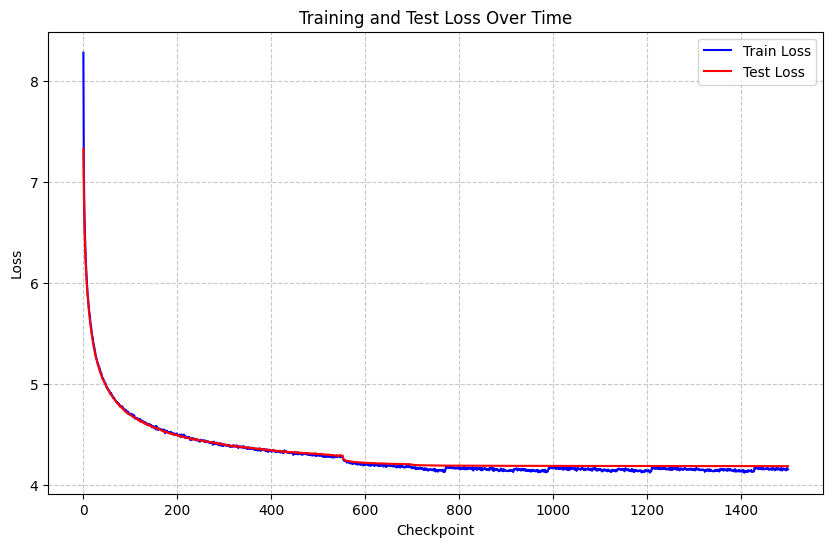

In [53]:
if use_existing_model:
    print("Exsiting model used, no loss curves shown.")
    plt.imshow(plt.imread("./loss_curve.png"))
else:
    plt.figure(figsize=(10, 6))
    plt.plot(losses, label="Train Loss", color='blue')
    plt.plot(test_losses, label="Test Loss", color='red')
    plt.xlabel('Checkpoint')
    plt.ylabel('Loss')
    plt.title('Training and Test Loss Over Time')
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.legend()
    plt.show()

In [54]:
if not use_existing_model:
    torch.save(model, f"./pretrain_final.pth")

### Inference with Pretrained Model

In [57]:
def inference(prompt, torch_model, max_new_tokens):
    torch_model.eval()
    with torch.no_grad():
        tokens = hf_tokenizer.encode(prompt)
        for _ in range(max_new_tokens):
            num_tokens = len(tokens)
            tokens_padded = tokens + [hf_tokenizer.eos_token_id] * (config.seq_len - num_tokens)
            tokens_padded = torch.tensor(tokens_padded).unsqueeze(0).to(device)
            logits = torch_model(tokens_padded)
            probabilities = torch.softmax(logits[0, num_tokens-1, :], dim=-1)
            predicted_token = torch.multinomial(probabilities, 1).item()
            tokens.append(predicted_token)
        return hf_tokenizer.decode(tokens)

In [58]:
print("Predicted:", inference("The president signed a bill to pass", model, max_new_tokens=20))
print("Predicted:", inference("There was a large division in", model, max_new_tokens=20))
print("Predicted:", inference("Reports are showing that", model, max_new_tokens=20))

Predicted: The president signed a bill to pass the trademark drug money program to combat the disease if they are not authorized to take office. Instead,
Predicted: There was a large division in a last-minute showdown can be said as Mr Fenty used Green Square to sing Father's leading
Predicted: Reports are showing that more miles per week will show, or any need should be done might send attacks for real patients.


### Supervised Fine Tuning

In [59]:
# Take the pretrained model and then go through supervised fine tuning
# Use the Fact Q&A dataset from Hugging Face

sft_ds = load_dataset("rubenroy/GammaCorpus-Fact-QA-450k", split="train", streaming=True)

def check_sft_dataset_exists():
    try:
        # Attempt to load the dataset with reuse_cache_if_exists mode
        load_dataset("parquet", data_files="fact_qa_train.parquet", split="train")
        load_dataset("parquet", data_files="fact_qa_test.parquet", split="train")
        return True
    except FileNotFoundError:
        return False

if not check_sft_dataset_exists():
    print("Tokenized supervised fine tuning dataset does not exist locally... Generating and saving to disk.")

    def tokenize_and_chunk(dataset, tokenizer, chunk_size=512, rows=1000):
        """
        Tokenizes and chunks the dataset into fixed-length 512-token segments.
        The 'target' sequence is shifted left by 1 token.
        Stops after generating `train_rows + test_rows` tokenized chunks.
        """
        row_count = 0

        for example in dataset:
            question_plus_answer = "<Question>" + example["question"] + "</Question>" + "<Answer>" + example["answer"] + "</Answer>"
            input_tokens = tokenizer(question_plus_answer, truncation=False, padding=False)['input_ids']

            if row_count >= rows:
                return

            if len(input_tokens) >= chunk_size:
                continue
            else:
                input_tokens = input_tokens +[tokenizer.eos_token_id] * (chunk_size - len(input_tokens))
            
            target_tokens = input_tokens[1:] + [tokenizer.eos_token_id]  # Shifted by 1 token

            yield {
                "input": input_tokens, 
                "target": target_tokens
            }
            
            row_count += 1

    # Set the max number of rows for training and testing
    TRAIN_ROWS = 440000  # Adjust as needed
    TEST_ROWS = 500   # Adjust as needed
    CHUNK_SIZE = 128

    # Convert generator to a Hugging Face Dataset
    tokenized_sft_dataset = Dataset.from_generator(lambda: tokenize_and_chunk(sft_ds, hf_tokenizer,chunk_size=CHUNK_SIZE, rows=TRAIN_ROWS + TEST_ROWS))

    # Split the dataset into `train` and `test`
    sft_dataset_splits = tokenized_sft_dataset.train_test_split(train_size=TRAIN_ROWS, test_size=TEST_ROWS, seed=42)

    # Save to disk
    sft_dataset_splits["train"].to_parquet("fact_qa_train.parquet")
    sft_dataset_splits["test"].to_parquet("fact_qa_test.parquet")

    print(f"✅ Saved {TRAIN_ROWS} train rows and {TEST_ROWS} test rows for supervised fine tuning.")
else:
    print("SFT Tokenized dataset already exists locally.")

Tokenized supervised fine tuning dataset does not exist locally... Generating and saving to disk.


Generating train split: 440500 examples [02:13, 3292.42 examples/s]
Creating parquet from Arrow format: 100%|██████████| 1/1 [00:00<00:00, 73.24ba/s]

✅ Saved 440000 train rows and 500 test rows for supervised fine tuning.


### Supervised Fine Tuning Training Loop

In [61]:
# Example config:
batch_size = 64
sequence_len = 128
num_steps = 50000
accumulation_steps = 100

# Reload the train and test datasets
train_ds = load_dataset("parquet", data_files="fact_qa_train.parquet", split="train")
test_ds = load_dataset("parquet", data_files="fact_qa_test.parquet", split="train")

# Convert dataset to PyTorch format
train_ds.set_format("torch", columns=["input", "target"])
test_ds.set_format("torch", columns=["input", "target"])

# Create DataLoaders for training and testing
train_dataloader = cycle(DataLoader(train_ds, batch_size=batch_size, shuffle=False))
test_dataloader = DataLoader(test_ds, batch_size=batch_size, shuffle=False)


use_existing_model = os.path.exists("./sft_final.pth")
# Check if pre-trained model exists
if use_existing_model:
    model = torch.load("./sft_final.pth", weights_only=False)
    print("Loaded fine tuned model from ./sft_final.pth, skipping training loop.")
else:
    model = torch.load("./pretrain_final.pth", weights_only=False)
    optimizer = torch.optim.Adam(model.parameters(), lr=5e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.2, patience=10, min_lr=5e-6, threshold=1e-4)

    losses = []
    test_losses = []
    accumulator = 0
    accumulator_loss = 0

    for i in range(num_steps):
        model.train()
        example = next(train_dataloader)
        train_input = example["input"].to(device)
        train_target = example["target"].to(device)
        logits = model(train_input)
        loss = F.cross_entropy(logits.view(-1, logits.size(-1)), train_target.view(-1))
        loss.backward()

        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        optimizer.step()
        optimizer.zero_grad()

        accumulator += 1
        accumulator_loss += loss.item()

        if accumulator >= accumulation_steps:
            losses.append(accumulator_loss/accumulation_steps)
            accumulator = 0
            accumulator_loss = 0
            model.eval()
            test_loss = 0
            test_accumulator = 0
            with torch.no_grad():
                for test_example in test_dataloader:
                    test_input = test_example["input"].to(device)
                    test_target = test_example["target"].to(device)
                    test_logits = model(test_input)
                    test_loss += F.cross_entropy(test_logits.view(-1, test_logits.size(-1)), test_target.view(-1)).item()
                    test_accumulator += 1
                test_losses.append(test_loss / test_accumulator)
                print(f"Step {i+1}/{num_steps}, Loss: {losses[-1]}, Test Loss: {test_losses[-1]}")
                test_dataloader = DataLoader(test_ds, batch_size=batch_size, shuffle=False)
                scheduler.step(test_losses[-1])

        if i+1 % 50000 == 0:
            torch.save(model.state_dict(), f"./sft_model_checkpoint_{i}.pt")


Generating train split: 440000 examples [00:01, 228929.46 examples/s]
Generating train split: 500 examples [00:00, 105130.94 examples/s]


Step 100/50000, Loss: 1.6221136248111725, Test Loss: 0.6879568174481392
Step 200/50000, Loss: 0.6702657669782639, Test Loss: 0.666757233440876
Step 300/50000, Loss: 0.6586272186040878, Test Loss: 0.6554909572005272
Step 400/50000, Loss: 0.6494063371419907, Test Loss: 0.6459713354706764
Step 500/50000, Loss: 0.6355940246582031, Test Loss: 0.6407946422696114
Step 600/50000, Loss: 0.6340951329469681, Test Loss: 0.6356813758611679
Step 700/50000, Loss: 0.6333903259038925, Test Loss: 0.630266547203064
Step 800/50000, Loss: 0.6309248602390289, Test Loss: 0.625726006925106
Step 900/50000, Loss: 0.6195582073926925, Test Loss: 0.620170533657074
Step 1000/50000, Loss: 0.6165850150585175, Test Loss: 0.6182383447885513
Step 1100/50000, Loss: 0.6172925251722335, Test Loss: 0.6147606447339058
Step 1200/50000, Loss: 0.6117067629098892, Test Loss: 0.6142444834113121
Step 1300/50000, Loss: 0.6102702128887176, Test Loss: 0.6121401339769363
Step 1400/50000, Loss: 0.6095616555213929, Test Loss: 0.60881318

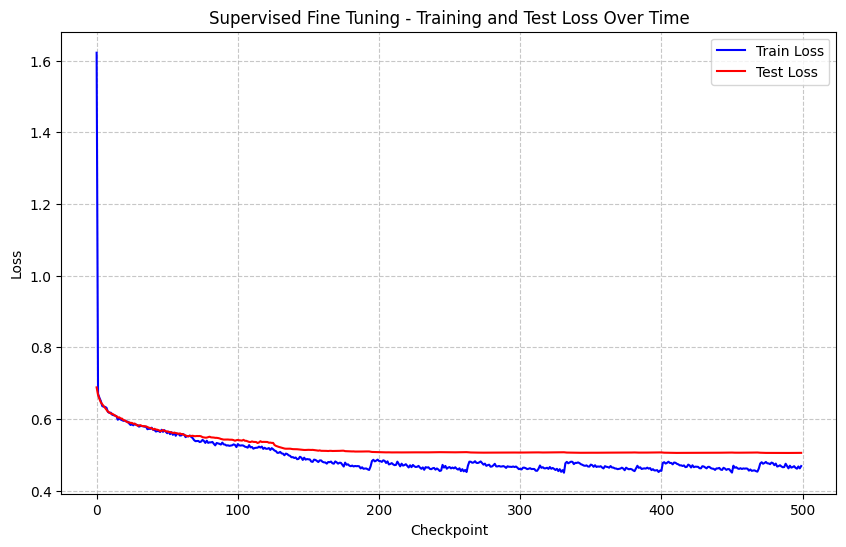

In [62]:
if use_existing_model:
    print("Existing model used, no loss curves shown.")
    plt.imshow(plt.imread("./sft_loss_curve.png"))
else:
    plt.figure(figsize=(10, 6))
    plt.plot(losses, label="Train Loss", color='blue')
    plt.plot(test_losses, label="Test Loss", color='red')
    plt.xlabel('Checkpoint')
    plt.ylabel('Loss')
    plt.title('Supervised Fine Tuning - Training and Test Loss Over Time')
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.legend()
    plt.show()

In [63]:
if not use_existing_model:
    torch.save(model, f"./sft_final.pth")

### Inference with Fine Tuned Model

In [75]:
def sft_inference(prompt,torch_model, max_new_tokens):
    torch_model.eval()
    prompt = "<Question>" + prompt + "</Question>" + "<Answer>" # Wrap the prompt in <Question> and start inference with <Answer>
    with torch.no_grad(): 
        tokens = hf_tokenizer.encode(prompt) # Tokenize the prompt
        for _ in range(max_new_tokens):
            if tokens[-1] == hf_tokenizer.eos_token_id: # Stop if we reach the end of the sequence
                break
            num_tokens = len(tokens) # 
            tokens_padded = tokens + [hf_tokenizer.eos_token_id] * (config.seq_len - num_tokens) # pad the sequence with eos token
            tokens_padded = torch.tensor(tokens_padded).unsqueeze(0).to(device) 
            logits = torch_model(tokens_padded) # Forward pass through the model
            probabilities = torch.softmax(logits[0, num_tokens-1, :], dim=-1) # Get the probabilities of the last token
            predicted_token = torch.argmax(probabilities).item() # Greedy decoding, change to sampling for more diversity
            tokens.append(predicted_token)
        
        # Strip the text to between the <Answer></Answer> tags
        full_answer = hf_tokenizer.decode(tokens)
        answer_start = full_answer.find("<Answer>") + len("<Answer>")
        answer_end = full_answer.find("</Answer>")
        return full_answer[answer_start:answer_end]

In [ ]:
print("Predicted:", sft_inference("Who is the most powerful leader in the west?", model, max_new_tokens=20))
print("Predicted:", sft_inference("What color is the sun?", model, max_new_tokens=20))
print("Predicted:", sft_inference("What color is the ocean", model, max_new_tokens=20))
print("Predicted:", sft_inference("How many planets are in the solar system", model, max_new_tokens=20))
print("Predicted:", sft_inference("What three countries are in north america?", model, max_new_tokens=20))
print("Predicted:", sft_inference("How many eyes do humans have?", model, max_new_tokens=20))

Predicted: Theodore Roosevelt
Predicted: Yellow
Predicted: Blue-bellied with black-footed ferrets
Predicted: Three stars
Predicted: Czech Republic and South Africa
Predicted: Two
Predicted: Kōkō
